# Large datasets: statistics, SasRec baselines, and semantic-ID training

This notebook covers the three large datasets of the `exp1-standard_params` experiment:

| Key | Dataset | Raw source |
|---|---|---|
| `beauty_2023` | Amazon Beauty 2023 | `data/raw/dataframe_format/reviews_beauty_2023.parquet` |
| `yambda_50m_listens` | Yambda 50M (flat, multi-event) | `data/raw/yambda/flat/50m/multi_event.parquet` |
| `yambda_500m_listens` | Yambda 500M (flat, multi-event) | `data/raw/yambda/flat/500m/multi_event.parquet` |

Contents:

1. **Dataset statistics** — computed directly from the raw parquet files (polars, streaming).
2. **SasRec metrics with interval estimates** — mean ± 95% CI across seeds 42/43/44, from
   `artifacts/exp1-standard_params/sasrec_*_metrics_summary.csv`.
3. **Semantic-ID (RQ-VAE) training analysis** — configs, loss curves, codebook usage and
   collision handling, from `artifacts/exp1-standard_params/semantic_id_training_report_*.json`
   and `datasets/semantic_ids/exp1-standard_params/*/`.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats as sps

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "flowrec").is_dir() and (p / "data").is_dir()
)

# Validated reference palette (first three categorical slots, light mode).
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, BASE, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb",
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 11, "figure.dpi": 110,
})

DATASETS = ["beauty_2023", "yambda_50m_listens", "yambda_500m_listens"]
LABELS = {
    "beauty_2023": "Amazon Beauty 2023",
    "yambda_50m_listens": "Yambda 50M",
    "yambda_500m_listens": "Yambda 500M",
}
COLORS = {
    "beauty_2023": C_BLUE,
    "yambda_50m_listens": C_ORANGE,
    "yambda_500m_listens": C_AQUA,
}
ARTIFACTS = REPO_ROOT / "artifacts/exp1-standard_params"
SEMANTIC_DIR = REPO_ROOT / "datasets/semantic_ids/exp1-standard_params"
print("repo root:", REPO_ROOT)

repo root: /Users/anaxagor/Documents/projects/flowrec


## 1. Dataset statistics

Statistics are computed from the raw interaction files. *Positives* follow each dataset's
training criterion from `configs/exp1-standard_params/`:

- Amazon Beauty 2023 — `verified_purchase == True`;
- Yambda — `event_type == 'listen' and played_ratio_pct >= 50`
  (other event types stay in the auxiliary interaction store).


In [2]:
# Amazon Beauty 2023 -- raw review interactions
amazon_lf = pl.scan_parquet(REPO_ROOT / "data/raw/dataframe_format/reviews_beauty_2023.parquet")
amazon_agg = amazon_lf.select(
    pl.len().alias("interactions"),
    pl.col("user_id").n_unique().alias("users"),
    pl.col("parent_asin").n_unique().alias("items"),
    pl.col("verified_purchase").sum().alias("positives"),
    pl.col("rating").mean().alias("rating_mean"),
    pl.from_epoch("timestamp", time_unit="ms").min().alias("first_event"),
    pl.from_epoch("timestamp", time_unit="ms").max().alias("last_event"),
).collect(engine="streaming").to_dicts()[0]
amazon_agg

{'interactions': 23911390,
 'users': 11325787,
 'items': 1028731,
 'positives': 21785369,
 'rating_mean': 4.111858783617347,
 'first_event': datetime.datetime(2000, 4, 1, 8, 10, 29),
 'last_event': datetime.datetime(2023, 9, 13, 16, 30, 23, 621000)}

In [3]:
# Yambda 50M / 500M -- one streaming pass per aggregate over the multi-event logs
YAMBDA_PATHS = {
    "yambda_50m_listens": REPO_ROOT / "data/raw/yambda/flat/50m/multi_event.parquet",
    "yambda_500m_listens": REPO_ROOT / "data/raw/yambda/flat/500m/multi_event.parquet",
}
POSITIVE = (pl.col("event_type") == "listen") & (pl.col("played_ratio_pct") >= 50)

yambda_agg, event_counts = {}, {}
for name, path in YAMBDA_PATHS.items():
    lf = pl.scan_parquet(path)
    yambda_agg[name] = lf.select(
        pl.len().alias("interactions"),
        pl.col("uid").n_unique().alias("users"),
        pl.col("item_id").n_unique().alias("items"),
        POSITIVE.sum().alias("positives"),
        pl.col("is_organic").cast(pl.Float64).mean().alias("organic_share"),
        ((pl.col("timestamp").max() - pl.col("timestamp").min()) / 86400).alias("timespan_days"),
    ).collect(engine="streaming").to_dicts()[0]
    event_counts[name] = (
        lf.group_by("event_type").len()
        .sort("len", descending=True)
        .collect(engine="streaming")
    )

# Items covered by the released audio embeddings (row count from parquet metadata)
emb_rows = pq.ParquetFile(REPO_ROOT / "data/raw/yambda/embeddings.parquet").metadata.num_rows
print(f"items with audio embeddings: {emb_rows:,}")
yambda_agg

items with audio embeddings: 7,721,749


{'yambda_50m_listens': {'interactions': 47790449,
  'users': 10000,
  'items': 934057,
  'positives': 29439278,
  'organic_share': 0.5205432575031885,
  'timespan_days': 300.9259259259259},
 'yambda_500m_listens': {'interactions': 480255564,
  'users': 100000,
  'items': 3004578,
  'positives': 294990476,
  'organic_share': 0.518324351990225,
  'timespan_days': 300.9259259259259}}

In [4]:
# Event-type breakdown of the Yambda multi-event logs
ev = pd.DataFrame({
    LABELS[name]: {
        r["event_type"]: r["len"] for r in event_counts[name].to_dicts()
    } for name in YAMBDA_PATHS
})
ev["50M share"] = ev[LABELS["yambda_50m_listens"]] / ev[LABELS["yambda_50m_listens"]].sum()
ev["500M share"] = ev[LABELS["yambda_500m_listens"]] / ev[LABELS["yambda_500m_listens"]].sum()
ev.style.format({LABELS["yambda_50m_listens"]: "{:,.0f}", LABELS["yambda_500m_listens"]: "{:,.0f}",
                 "50M share": "{:.2%}", "500M share": "{:.2%}"})

,Yambda 50M,Yambda 500M,50M share,500M share
listen,"46,467,212","466,512,103",97.23%,97.14%
like,"881,456","9,033,960",1.84%,1.88%
unlike,"312,972","3,309,936",0.65%,0.69%
dislike,"107,776","1,128,113",0.23%,0.23%
undislike,"21,033","271,452",0.04%,0.06%


In [5]:
# Interactions per user / per item (raw logs)
def entity_quantiles(lf, key):
    counts = lf.group_by(key).len().collect(engine="streaming")["len"]
    return {
        "mean": float(counts.mean()), "median": float(counts.median()),
        "p90": float(counts.quantile(0.9)), "max": int(counts.max()),
    }

per_entity = {}
per_entity["beauty_2023"] = {
    "per user": entity_quantiles(amazon_lf, "user_id"),
    "per item": entity_quantiles(amazon_lf, "parent_asin"),
}
for name, path in YAMBDA_PATHS.items():
    lf = pl.scan_parquet(path)
    per_entity[name] = {
        "per user": entity_quantiles(lf, "uid"),
        "per item": entity_quantiles(lf, "item_id"),
    }

pe = pd.DataFrame({
    (LABELS[d], side): per_entity[d][side] for d in DATASETS for side in ("per user", "per item")
}).T
pe.style.format({"mean": "{:,.1f}", "median": "{:,.0f}", "p90": "{:,.0f}", "max": "{:,.0f}"})

### Sequence lengths

Training sequences are built from each user's **positives**, so the first table reports
positives-per-user from the raw logs (mean / median and min–max range). For **Yambda 500M** the
datamodule trains on a **2-month recency window** (`hf_recent_months: 2`), so a second row
replicates that window before counting.

The second table shows history lengths **after the full datamodule pipeline** (positive
criterion, embedding coverage, 5-core filters, splitting), as recorded in the SasRec
`training_summary.json`. The Yambda 500M run is incomplete: no training summary was written, and
its `best.pt.json` best-epoch log records no sequence-length statistics — only the model's
truncation cap `max_history_len`, which is what the table takes from it.


In [6]:
# Raw sequence lengths: positives per user
def seq_stats(lf, user_key, positive_expr):
    lens = lf.filter(positive_expr).group_by(user_key).len().collect(engine="streaming")["len"]
    return {
        "mean": float(lens.mean()), "median": float(lens.median()),
        "min": int(lens.min()), "max": int(lens.max()),
        "users with ≥1 positive": len(lens),
    }

seq_rows = {(LABELS["beauty_2023"], "raw positives/user"):
            seq_stats(amazon_lf, "user_id", pl.col("verified_purchase"))}
for name, path in YAMBDA_PATHS.items():
    seq_rows[(LABELS[name], "raw positives/user")] = seq_stats(
        pl.scan_parquet(path), "uid", POSITIVE)

# Yambda 500M actually trains on the last 2 calendar months (hf_recent_months: 2);
# replicate the datamodule's window: [max_ts - 2 months, max_ts]
lf500 = pl.scan_parquet(YAMBDA_PATHS["yambda_500m_listens"])
ts_max = lf500.select(pl.col("timestamp").max()).collect(engine="streaming").item()
cutoff = int((pd.Timestamp(ts_max, unit="s") - pd.DateOffset(months=2)).timestamp())
seq_rows[(LABELS["yambda_500m_listens"], "raw positives/user, 2-month training window")] = (
    seq_stats(lf500.filter(pl.col("timestamp") >= cutoff), "uid", POSITIVE))

seq_df = pd.DataFrame(seq_rows).T
seq_df.style.format({"mean": "{:,.1f}", "median": "{:,.0f}", "min": "{:,.0f}",
                     "max": "{:,.0f}", "users with ≥1 positive": "{:,.0f}"})

In [7]:
# Post-filter history lengths recorded by the datamodule
CKPT = REPO_ROOT / "checkpoints/exp1-standard_params/sasrec"
SUMMARY_PATHS = {
    "beauty_2023": CKPT / "amazon-2023/beauty_2023/training_summary.json",
    "yambda_50m_listens": CKPT / "yambda/yambda_50m_listens/training_summary.json",
}
BEST_PT_PATHS = {
    "beauty_2023": CKPT / "amazon-2023/beauty_2023/seed_42/best.pt.json",
    "yambda_50m_listens": CKPT / "yambda/yambda_50m_listens/seed_42/best.pt.json",
    "yambda_500m_listens": CKPT / "yambda/yambda_500m_listens/seed_42/best.pt.json",
}

hist_rows = {}
for name in DATASETS:
    cap = json.loads(BEST_PT_PATHS[name].read_text())["model_config"]["max_history_len"]
    if name in SUMMARY_PATHS:
        ds = json.loads(SUMMARY_PATHS[name].read_text())["runs"][0]["dataset"]
        hist_rows[LABELS[name]] = {
            "mean history len": ds["mean_history_len"],
            "mean train/val/test": (f"{ds['mean_train_history_len']:.1f} / "
                                    f"{ds['mean_val_history_len']:.1f} / "
                                    f"{ds['mean_test_history_len']:.1f}"),
            "model cap (max_history_len)": cap,
            "users (post-filter)": ds["num_users"],
        }
    else:  # yambda_500m: run incomplete -> no summary; best.pt.json has only the cap
        hist_rows[LABELS[name]] = {
            "mean history len": np.nan,
            "mean train/val/test": "not logged in best.pt.json",
            "model cap (max_history_len)": cap,
            "users (post-filter)": np.nan,
        }

pd.DataFrame(hist_rows).T.style.format(
    {"mean history len": "{:,.1f}", "model cap (max_history_len)": "{:,.0f}",
     "users (post-filter)": "{:,.0f}"}, na_rep="—")

,mean history len,mean train/val/test,model cap (max_history_len),users (post-filter)
Amazon Beauty 2023,6.0,5.1 / 6.0 / 7.0,20,"662,540"
Yambda 50M,48.3,48.5 / 47.3 / 47.4,50,"8,775"
Yambda 500M,—,not logged in best.pt.json,50,—


In [8]:
# Combined statistics table
amazon_days = (amazon_agg["last_event"] - amazon_agg["first_event"]).days

# Post-filter footprint of the exp1 pipeline (5-core filters + embedding coverage):
# eval users from the SasRec metric summaries, catalog items from the tokenizer reports.
sid_report = {}
for name in DATASETS:
    with open(ARTIFACTS / f"semantic_id_training_report_{name}.json") as fh:
        sid_report[name] = json.load(fh)["datasets"][0]

eval_users = {"beauty_2023": 662_540, "yambda_50m_listens": 8_775, "yambda_500m_listens": None}

rows = {}
for name in DATASETS:
    agg = amazon_agg if name == "beauty_2023" else yambda_agg[name]
    seq = seq_rows[(LABELS[name], "raw positives/user")]
    rows[LABELS[name]] = {
        "interactions": agg["interactions"],
        "users": agg["users"],
        "items": agg["items"],
        "positives": agg["positives"],
        "positive share": agg["positives"] / agg["interactions"],
        "density": agg["interactions"] / (agg["users"] * agg["items"]),
        "mean inter./user": agg["interactions"] / agg["users"],
        "seq len mean (positives/user)": seq["mean"],
        "seq len range": f"{seq['min']:,}–{seq['max']:,}",
        "timespan (days)": amazon_days if name == "beauty_2023" else agg["timespan_days"],
        "eval users (post-filter)": eval_users[name],
        "tokenizer catalog items": sid_report[name].get(
            "num_catalog_items", sid_report[name]["num_items"]),
    }

stats_df = pd.DataFrame(rows)
stats_df.style.format(lambda v: v if isinstance(v, str) else ("—" if v is None else (
    f"{v:.3e}" if isinstance(v, float) and v < 0.001 else
    (f"{v:,.1f}" if isinstance(v, float) else f"{v:,.0f}"))), na_rep="—")

,Amazon Beauty 2023,Yambda 50M,Yambda 500M
interactions,"23,911,390","47,790,449","480,255,564"
users,"11,325,787","10,000","100,000"
items,"1,028,731","934,057","3,004,578"
positives,"21,785,369","29,439,278","294,990,476"
positive share,0.9,0.6,0.6
density,2.052e-06,0.0,0.0
mean inter./user,2.1,"4,779.0","4,802.6"
seq len mean (positives/user),2.0,"3,196.8","3,212.6"
seq len range,1–424,"1–26,959","1–27,573"
timespan (days),"8,565",300.9,300.9


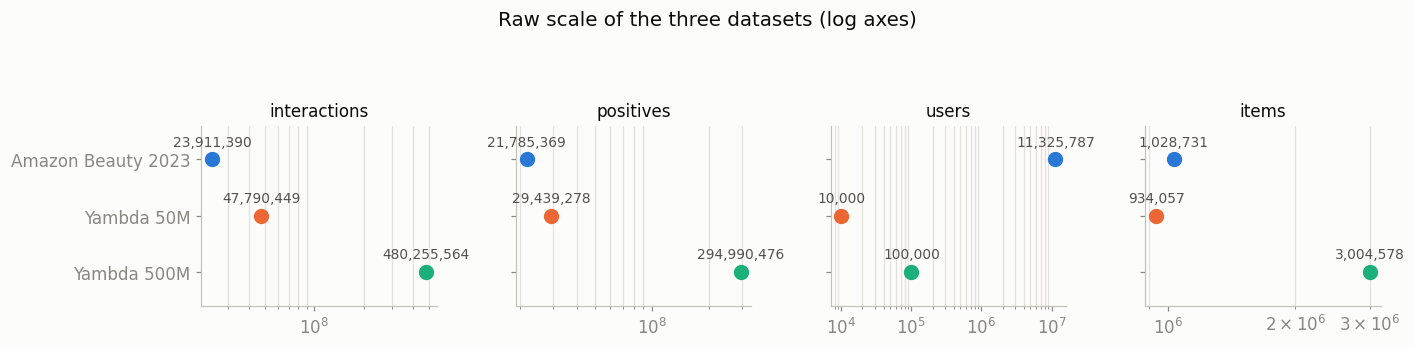

In [9]:
# Scale comparison (dot plot, log axis -- position encoding, not bar length)
panels = ["interactions", "positives", "users", "items"]
fig, axes = plt.subplots(1, len(panels), figsize=(13, 2.8), sharey=True)
ypos = np.arange(len(DATASETS))[::-1]
for ax, metric in zip(axes, panels):
    vals = [stats_df.loc[metric, LABELS[d]] for d in DATASETS]
    for y, d, v in zip(ypos, DATASETS, vals):
        ax.plot([v], [y], "o", ms=9, color=COLORS[d], zorder=3)
        ax.annotate(f"{v:,.0f}", (v, y), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=9, color=INK2)
    ax.set_xscale("log")
    ax.set_title(metric, fontsize=11)
    ax.set_yticks(ypos, [LABELS[d] for d in DATASETS])
    ax.set_ylim(-0.6, len(DATASETS) - 0.4)
    ax.grid(axis="x", which="both")
    ax.grid(axis="y", visible=False)
fig.suptitle("Raw scale of the three datasets (log axes)", y=1.12, fontsize=13)
plt.tight_layout()
plt.show()

**Reading the numbers.** The three corpora differ not just in size but in shape: Amazon Beauty
2023 is an extremely sparse review stream (most users leave a handful of reviews), while Yambda
is a dense music-listening log — few users, very long histories. Two pipeline details matter
downstream:

- For **Yambda 500M** the exp1 config applies a 2-month recency window (`hf_recent_months: 2`),
  which keeps the SasRec/tokenizer catalog near 435k items; without it the catalog would be
  ~790k+ items and dense-causal SasRec training would not fit an 80 GB GPU.
- Yambda items must have an audio embedding (`drop_items_missing_embedding: true`), and only
  *listens with ≥50% play ratio* become SasRec positives; likes/dislikes/short listens go to the
  auxiliary interaction store.


## 2. SasRec: interval estimates across seeds

Each dataset was trained with seeds **42 / 43 / 44** (`scripts/exp1-standard-params/run_sasrec_all.py`);
per-seed metrics live in `artifacts/exp1-standard_params/sasrec_*_metrics_summary.csv`.
Below: **mean ± half-width of the 95% confidence interval** (Student's t, df = n−1) for every
reported metric — HR@k, NDCG@k, catalog Coverage@k and Average Recommendation Popularity (ARP@k).

> **Yambda 500M caveat:** only the seed-42 run has finished (checkpoint
> `checkpoints/exp1-standard_params/sasrec/yambda/yambda_500m_listens/seed_42`); there is no test
> metrics summary yet, so no across-seed interval is possible. Its best-epoch *validation*
> metrics are shown separately below.


In [10]:
sasrec_csvs = {
    "beauty_2023": ARTIFACTS / "sasrec_amazon_2023_metrics_summary.csv",
    "yambda_50m_listens": ARTIFACTS / "sasrec_yambda_50m_listens_metrics_summary.csv",
}
raw = pd.concat([pd.read_csv(p) for p in sasrec_csvs.values()], ignore_index=True)
METRICS = [c for c in raw.columns if "@" in c]
print("seeds per dataset/split:")
print(raw.groupby(["dataset", "split"]).size())

grp = raw.groupby(["dataset", "split"])[METRICS]
mean, std, n = grp.mean(), grp.std(ddof=1), grp.size()
tcrit = sps.t.ppf(0.975, n - 1)
halfwidth = std.mul(tcrit / np.sqrt(n), axis=0)

def ci_table(split):
    out = {}
    for ds in sasrec_csvs:
        row = {}
        for m in METRICS:
            mu, hw = mean.loc[(ds, split), m], halfwidth.loc[(ds, split), m]
            dec = 1 if m.startswith("ARP") else 4
            row[m] = f"{mu:.{dec}f} ± {hw:.{dec}f}"
        out[LABELS[ds]] = row
    return pd.DataFrame(out).T

print("\nTEST split — mean ± 95% CI (3 seeds):")
ci_table("test")

seeds per dataset/split:
dataset             split     
beauty_2023         test          3
                    validation    3
yambda_50m_listens  test          3
                    validation    3
dtype: int64

TEST split — mean ± 95% CI (3 seeds):


,HR@5,NDCG@5,Coverage@5,ARP@5,HR@10,NDCG@10,Coverage@10,ARP@10,HR@20,NDCG@20,Coverage@20,ARP@20
Amazon Beauty 2023,0.0499 ± 0.0003,0.0395 ± 0.0002,0.7734 ± 0.0229,1112.3 ± 24.8,0.0619 ± 0.0005,0.0434 ± 0.0002,0.7968 ± 0.0267,1086.7 ± 26.7,0.0774 ± 0.0008,0.0473 ± 0.0003,0.8236 ± 0.0322,998.4 ± 28.2
Yambda 50M,0.1206 ± 0.0053,0.0839 ± 0.0030,0.1748 ± 0.0035,689.0 ± 42.5,0.1678 ± 0.0068,0.0991 ± 0.0033,0.2664 ± 0.0040,724.0 ± 43.3,0.2200 ± 0.0048,0.1123 ± 0.0026,0.3772 ± 0.0075,748.8 ± 43.2


In [11]:
print("VALIDATION split — mean ± 95% CI (3 seeds):")
ci_table("validation")

VALIDATION split — mean ± 95% CI (3 seeds):


,HR@5,NDCG@5,Coverage@5,ARP@5,HR@10,NDCG@10,Coverage@10,ARP@10,HR@20,NDCG@20,Coverage@20,ARP@20
Amazon Beauty 2023,0.0378 ± 0.0004,0.0253 ± 0.0002,0.8254 ± 0.0366,1079.9 ± 26.0,0.0520 ± 0.0003,0.0299 ± 0.0002,0.8501 ± 0.0420,1072.2 ± 30.3,0.0697 ± 0.0005,0.0343 ± 0.0002,0.8749 ± 0.0449,997.1 ± 31.8
Yambda 50M,0.1209 ± 0.0093,0.0829 ± 0.0041,0.1767 ± 0.0041,679.4 ± 36.3,0.1710 ± 0.0091,0.0991 ± 0.0046,0.2687 ± 0.0053,717.3 ± 42.0,0.2256 ± 0.0041,0.1129 ± 0.0034,0.3797 ± 0.0065,742.5 ± 45.0


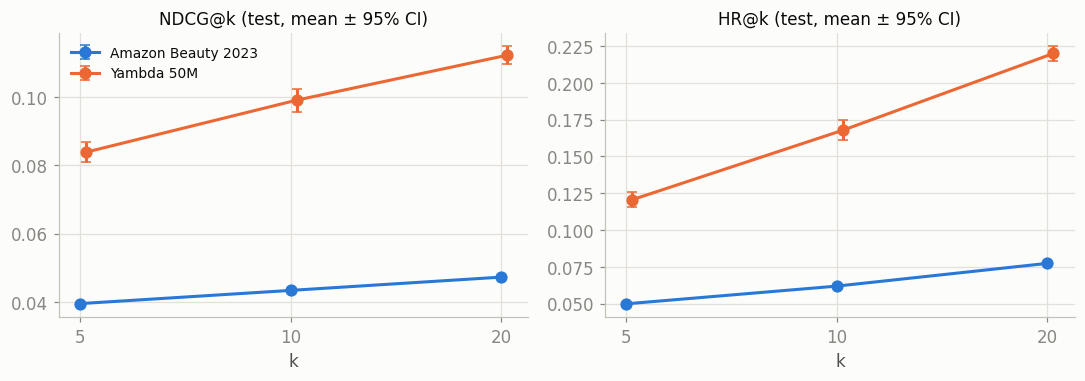

In [12]:
# Ranking metrics with 95% CI error bars (test split)
KS = [5, 10, 20]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, fam in zip(axes, ["NDCG", "HR"]):
    for i, ds in enumerate(sasrec_csvs):
        mus = [mean.loc[(ds, "test"), f"{fam}@{k}"] for k in KS]
        hws = [halfwidth.loc[(ds, "test"), f"{fam}@{k}"] for k in KS]
        x = np.array(KS) * (1 + 0.02 * i)  # slight offset so error bars don't overlap
        ax.errorbar(x, mus, yerr=hws, color=COLORS[ds], lw=2, ms=7, marker="o",
                    capsize=3, label=LABELS[ds])
    ax.set_xscale("log")
    ax.set_xticks(KS, [str(k) for k in KS])
    ax.set_xlabel("k")
    ax.set_title(f"{fam}@k (test, mean ± 95% CI)", fontsize=11)
    ax.minorticks_off()
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [13]:
# Yambda 500M -- the single finished seed (42): best-epoch validation metrics
ck_path = (REPO_ROOT / "checkpoints/exp1-standard_params/sasrec/yambda"
           / "yambda_500m_listens/seed_42/best.pt.json")
ck = json.loads(ck_path.read_text())
state = ck["trainer_state"]
hist = [h for h in state["history"] if "val" in h]
best = max(hist, key=lambda h: h["val"]["val/sft/ndcg@10"])

val_tbl = pd.DataFrame({
    f"@{k}": {
        "Recall (=HR)": best["val"][f"val/sft/recall@{k}"],
        "NDCG": best["val"][f"val/sft/ndcg@{k}"],
    } for k in [1, 5, 10, 20]
})
print(f"Yambda 500M, seed 42 only — {len(hist)} epochs run, best in-history epoch "
      f"{best['epoch']} (checkpoint monitor val/sft/ndcg@10 = {state['best_metric']:.4f}); "
      f"single seed → no interval estimate")
val_tbl.style.format("{:.4f}")

Yambda 500M, seed 42 only — 80 epochs run, best in-history epoch 77 (checkpoint monitor val/sft/ndcg@10 = 0.0982); single seed → no interval estimate


,@1,@5,@10,@20
Recall (=HR),0.0471,0.1176,0.1639,0.2193
NDCG,0.0471,0.0831,0.0980,0.1119


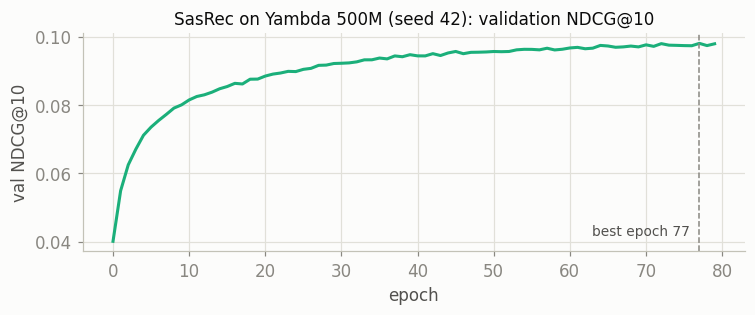

In [14]:
# Validation NDCG@10 trajectory of the Yambda 500M run
epochs = [h["epoch"] for h in hist]
ndcg10 = [h["val"]["val/sft/ndcg@10"] for h in hist]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(epochs, ndcg10, lw=2, color=C_AQUA)
ax.axvline(best["epoch"], color=MUTED, lw=1, ls="--")
ax.annotate(f"best epoch {best['epoch']}", (best["epoch"], min(ndcg10)),
            xytext=(-6, 4), textcoords="offset points", ha="right", fontsize=9, color=INK2)
ax.set_xlabel("epoch"); ax.set_ylabel("val NDCG@10")
ax.set_title("SasRec on Yambda 500M (seed 42): validation NDCG@10", fontsize=11)
plt.tight_layout(); plt.show()

## 3. How the semantic identifiers were trained

Semantic IDs come from an **RQ-VAE tokenizer** (`scripts/exp1-standard-params/train_tokenizer_all.py`,
config `configs/exp1-standard_params/semantic_ids.yaml`). All three datasets share the same
standard-params architecture; only the **input embeddings** differ:

- **Amazon Beauty 2023** — 384-d text embeddings from `sentence-transformers/all-MiniLM-L6-v2`
  over item text (title + description + features + categories + details, masked-mean pooling);
- **Yambda 50M / 500M** — the released 128-d audio embeddings (`data/raw/yambda/embeddings.parquet`,
  un-normalized).

Each item gets 3 codebook tokens (levels of 256 codes, K-Means-initialized, with level-offset
token IDs) plus a 4th disambiguation token appended for items whose 3-token prefix collides
(`collision_policy: append`).


In [15]:
arch_rows = {}
for name in DATASETS:
    r = sid_report[name]
    cs = r["collision_stats"]
    arch_rows[LABELS[name]] = {
        "embedding source": "MiniLM-L6-v2 text (384d)" if name == "beauty_2023"
                            else "Yambda audio (128d)",
        "items tokenized": r["num_items"],
        "RQ-VAE": (f"{r['rqvae']['num_codebooks']} × {r['rqvae']['codebook_size']} codes, "
                   f"latent {r['rqvae']['latent_dim']}, "
                   f"hidden {'-'.join(map(str, r['rqvae']['hidden_dims']))}"),
        "epochs run": r["train"]["epochs"],
        "best epoch": r["best_epoch"],
        "best val loss": r["best_val_loss"],
        "train time (h)": r["train_seconds"] / 3600,
        "colliding items (3-token prefix)": cs["num_collisions_before"],
        "collision share": cs["num_collisions_before"] / cs["num_items"],
        "max collision group": cs["max_collision_group_size"],
        "unique IDs after append": r["unique_semantic_ids"],
    }
arch_df = pd.DataFrame(arch_rows)
arch_df.style.format(lambda v: f"{v:,.0f}" if isinstance(v, int) else (
    f"{v:.2%}" if isinstance(v, float) and v < 1 else
    (f"{v:,.2f}" if isinstance(v, float) else v)))

,Amazon Beauty 2023,Yambda 50M,Yambda 500M
embedding source,MiniLM-L6-v2 text (384d),Yambda audio (128d),Yambda audio (128d)
items tokenized,"163,050","133,747","434,657"
RQ-VAE,"3 × 256 codes, latent 32, hidden 512-256-128","3 × 256 codes, latent 32, hidden 512-256-128","3 × 256 codes, latent 32, hidden 512-256-128"
epochs run,500,500,500
best epoch,23,11,4
best val loss,0.63%,0.20%,0.21%
train time (h),2.67,1.22,11.84
colliding items (3-token prefix),"15,569","13,877","79,515"
collision share,9.55%,10.38%,18.29%
max collision group,17,99,233


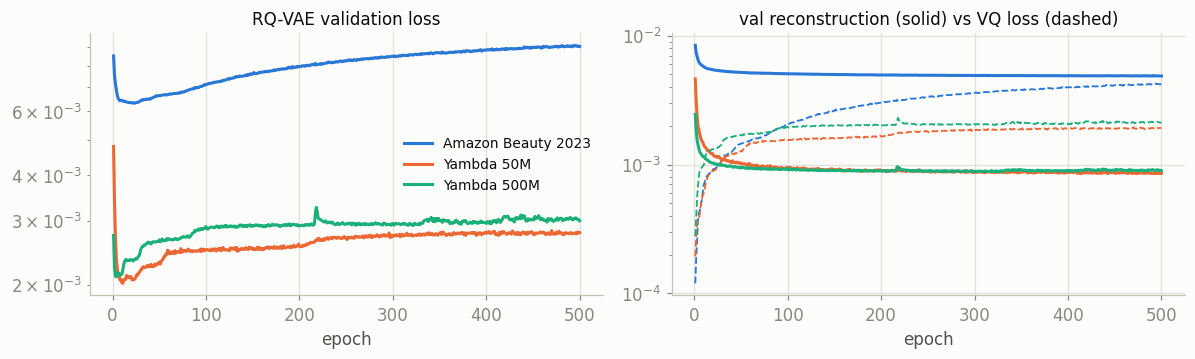

Amazon Beauty 2023     dead codes reach 0 at epoch  4; best val loss at epoch  23; final val loss 0.00906 vs best 0.00631
Yambda 50M             dead codes reach 0 at epoch  3; best val loss at epoch  11; final val loss 0.00278 vs best 0.00202
Yambda 500M            dead codes reach 0 at epoch  2; best val loss at epoch   4; final val loss 0.00300 vs best 0.00210


In [16]:
# Training dynamics from datasets/semantic_ids/exp1-standard_params/<dataset>/training_log.jsonl
logs = {}
for name in DATASETS:
    with open(SEMANTIC_DIR / name / "training_log.jsonl") as fh:
        logs[name] = pd.DataFrame([json.loads(l) for l in fh])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name in DATASETS:
    df = logs[name]
    axes[0].plot(df["epoch"], df["val_loss"], lw=2, color=COLORS[name], label=LABELS[name])
    axes[1].plot(df["epoch"], df["val_recon_loss"], lw=2, color=COLORS[name])
    axes[1].plot(df["epoch"], df["val_vq_loss"], lw=1.2, ls="--", color=COLORS[name])
axes[0].set_yscale("log"); axes[1].set_yscale("log")
axes[0].set_title("RQ-VAE validation loss", fontsize=11)
axes[1].set_title("val reconstruction (solid) vs VQ loss (dashed)", fontsize=11)
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

for name in DATASETS:
    df = logs[name]
    dead_cols = [c for c in df.columns if "dead_codes" in c]
    alive_from = int(df.loc[(df[dead_cols].sum(axis=1) == 0)].iloc[0]["epoch"])
    best_ep = sid_report[name]["best_epoch"]
    print(f"{LABELS[name]:<22} dead codes reach 0 at epoch {alive_from:>2}; "
          f"best val loss at epoch {best_ep:>3}; "
          f"final val loss {df['val_loss'].iloc[-1]:.5f} vs best {sid_report[name]['best_val_loss']:.5f}")

In [17]:
# Codebook usage: decode the level-offset tokens back to raw codes per level
CODEBOOK = 256
usage_rows, usage_curves, prefix_stats = {}, {}, {}
for name in DATASETS:
    with open(SEMANTIC_DIR / name / "semantic_ids.json") as fh:
        ids = np.array(list(json.load(fh).values()))
    levels = [ids[:, l] - l * CODEBOOK for l in range(3)]
    usage_curves[name] = []
    for l, codes in enumerate(levels):
        counts = np.bincount(codes, minlength=CODEBOOK)
        p = counts / counts.sum()
        perplexity = float(np.exp(-(p[p > 0] * np.log(p[p > 0])).sum()))
        usage_rows[(LABELS[name], f"level {l + 1}")] = {
            "codes used / 256": int((counts > 0).sum()),
            "perplexity": perplexity,
            "top-10 codes hold": float(np.sort(p)[::-1][:10].sum()),
        }
        usage_curves[name].append(np.sort(p)[::-1])
    # 3-token prefix collision structure
    prefix = ids[:, 0] * CODEBOOK**2 + (ids[:, 1] - CODEBOOK) * CODEBOOK + (ids[:, 2] - 2 * CODEBOOK)
    _, sizes = np.unique(prefix, return_counts=True)
    prefix_stats[LABELS[name]] = {
        "items": len(ids),
        "unique 3-token prefixes": len(sizes),
        "items sharing a prefix": int(sizes[sizes > 1].sum()),
        "share": float(sizes[sizes > 1].sum() / len(ids)),
        "max group size": int(sizes.max()),
    }

pd.DataFrame(usage_rows).T.style.format(
    {"codes used / 256": "{:.0f}", "perplexity": "{:,.1f}", "top-10 codes hold": "{:.1%}"})

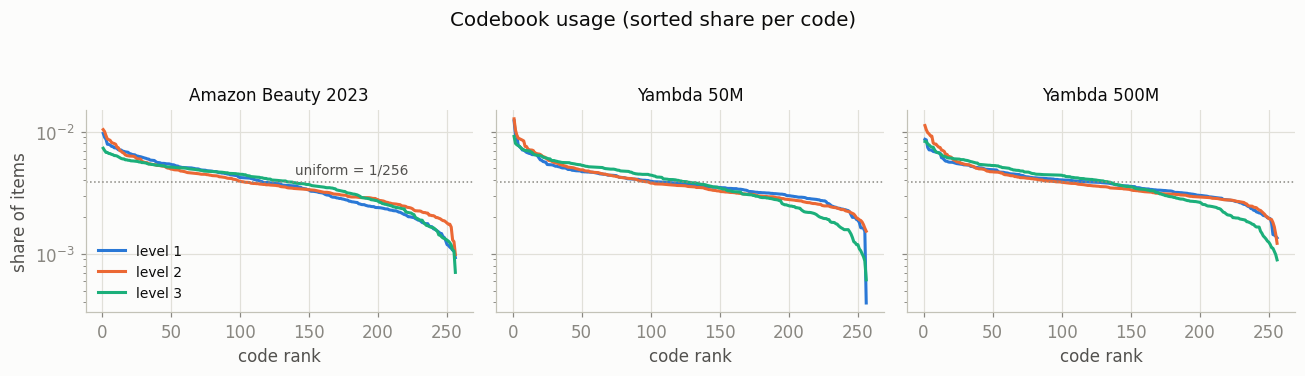

In [18]:
# Sorted per-code usage share, by residual level
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, name in zip(axes, DATASETS):
    for l, curve in enumerate(usage_curves[name]):
        ax.plot(np.arange(1, CODEBOOK + 1), curve, lw=2,
                color=[C_BLUE, C_ORANGE, C_AQUA][l], label=f"level {l + 1}")
    ax.axhline(1 / CODEBOOK, color=MUTED, lw=1, ls=":")
    ax.set_yscale("log")
    ax.set_title(LABELS[name], fontsize=11)
    ax.set_xlabel("code rank")
axes[0].set_ylabel("share of items")
axes[0].annotate("uniform = 1/256", (140, 1 / CODEBOOK), xytext=(0, 5),
                 textcoords="offset points", fontsize=9, color=INK2)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Codebook usage (sorted share per code)", y=1.06, fontsize=13)
plt.tight_layout(); plt.show()

In [19]:
pd.DataFrame(prefix_stats).T.style.format(
    {"items": "{:,.0f}", "unique 3-token prefixes": "{:,.0f}",
     "items sharing a prefix": "{:,.0f}", "share": "{:.1%}", "max group size": "{:,.0f}"})

,items,unique 3-token prefixes,items sharing a prefix,share,max group size
Amazon Beauty 2023,"163,050","147,481","27,066",16.6%,17
Yambda 50M,"133,747","119,870","22,873",17.1%,99
Yambda 500M,"434,657","355,142","125,032",28.8%,233


### Takeaways — semantic-ID training

- **Identical standard-params recipe, different modalities.** All three tokenizers are
  3-level RQ-VAEs (256 codes/level, latent 32, hidden 512-256-128, AdamW lr 1e-3, batch 1024,
  500 epochs, K-Means codebook init, dead-code reset every epoch). Beauty 2023 encodes MiniLM
  *text* embeddings (384-d); both Yambda variants encode the released *audio* embeddings (128-d).
- **The best model comes very early.** Best validation loss lands at epoch 23 / 11 / 4
  (Beauty / Y50M / Y500M) and the exported tokenizer is that checkpoint. Afterwards total val
  loss drifts up ~30–45% by epoch 500: reconstruction keeps improving slightly while the VQ
  (codebook/commitment) term grows — the 500-epoch standard schedule is far longer than needed.
- **Healthy codebooks at every scale.** Dead codes vanish within the first 2–4 epochs and all
  256 codes stay in use at every level; usage perplexity is 232–244 vs the uniform bound of 256.
- **Collisions grow with catalog size.** 9.5% of Beauty items, 10.4% of Yambda 50M and 18.3%
  of Yambda 500M items share a 3-token prefix (max group 233 on Y500M — consistent with
  duplicate/near-duplicate audio embeddings). The `append` policy adds a 4th disambiguation
  token, so every item still gets a unique semantic ID.
